# 03 · Modelagem, avaliação e publicação

Seleciona os regimes, calibra o detector de anomalias e publica a versão final do modelo. Cada decisão é explicada antes da execução, e o período de teste permanece reservado até a avaliação final.

**Fluxo:** comparar candidatos na validação → congelar a versão base → avaliar o teste → validar o filtro de transições → publicar a versão final v1.1.

In [1]:
import hashlib
import json
import platform
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)


def find_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Raiz do projeto não encontrada.")


ROOT = find_root(Path.cwd())
sys.path.insert(0, str(ROOT / "src"))

from regime_anomaly import modeling as md
from regime_anomaly import preprocessing as pp
from regime_anomaly.artifacts import write_manifest
from regime_anomaly.config import (
    IMAGES_DIR,
    METADATA_DIR,
    MODELS_DIR,
    PROCESSED_DIR,
    RANDOM_STATE,
    TABLES_DIR,
    ensure_artifact_dirs,
)
from regime_anomaly.data import DEFAULT_DATASET, load_data

ensure_artifact_dirs()
HIGH_CONTRAST_PALETTE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]
REGIME_COLORS = HIGH_CONTRAST_PALETTE[:3]
sns.set_theme(style="whitegrid", palette=HIGH_CONTRAST_PALETTE)
pd.set_option("display.max_columns", 30)

SEEDS = [RANDOM_STATE, 7, 123, 2024, 31415]
N_BOOTSTRAP = 10
SILHOUETTE_SAMPLE = 5_000
MIN_BOOTSTRAP_ARI = 0.80
MIN_CLUSTER_SHARE = 0.05
ALERT_RATE = 0.01
REGIME_SETS = ["regime", "regime_with_calendar"]


def save_figure(fig, name: str) -> None:
    fig.savefig(IMAGES_DIR / name, dpi=150, bbox_inches="tight")


def save_table(frame: pd.DataFrame, name: str, index: bool = True) -> None:
    frame.to_csv(TABLES_DIR / name, index=index, encoding="utf-8-sig")

# load_data() mantém os nomes originais da UCI; o protocolo trabalha em snake_case.
LABEL_COLUMN = pp.LABEL


## 1. Dados preparados

As partições são recalculadas com `prepare_frame` e conferidas com o hash registrado
pelo notebook 02, garantindo que os dois notebooks usam a mesma base.

In [2]:
raw_sha256 = hashlib.sha256(DEFAULT_DATASET.read_bytes()).hexdigest()
preprocessing_meta = json.loads((METADATA_DIR / "preprocessing.json").read_text(encoding="utf-8"))
assert raw_sha256 == preprocessing_meta["fonte"]["sha256"], (
    "Base diferente da usada no notebook 02."
)

prepared, _ = pp.prepare_frame(load_data())
splits = {
    name: prepared[prepared[pp.SPLIT_COLUMN] == name].reset_index(drop=True)
    for name in pp.SPLIT_NAMES
}
train, validation, test = (splits[name] for name in pp.SPLIT_NAMES)
print({name: len(frame) for name, frame in splits.items()})

fitted_preprocessors, transformed = {}, {}
for feature_set in [*REGIME_SETS, "anomaly"]:
    columns = pp.feature_columns(feature_set)
    preprocessor = pp.build_feature_preprocessor(feature_set).fit(train[columns])
    fitted_preprocessors[feature_set] = preprocessor
    transformed[feature_set] = {
        name: preprocessor.transform(frame[columns]) for name, frame in splits.items()
    }

{'train': 23328, 'validation': 5856, 'test': 5856}


## 2. Geometria na validação

In [3]:
def internal_metrics(features: np.ndarray, labels: np.ndarray) -> dict[str, float]:
    if len(np.unique(labels)) < 2:
        return {
            "silhouette": np.nan,
            "davies_bouldin": np.nan,
            "calinski_harabasz": np.nan,
            "menor_grupo": 1.0,
        }
    return {
        "silhouette": silhouette_score(
            features,
            labels,
            sample_size=min(SILHOUETTE_SAMPLE, len(labels)),
            random_state=RANDOM_STATE,
        ),
        "davies_bouldin": davies_bouldin_score(features, labels),
        "calinski_harabasz": calinski_harabasz_score(features, labels),
        "menor_grupo": float(np.bincount(labels, minlength=md.N_REGIMES).min() / len(labels)),
    }


reference_models, rows = {}, []
for feature_set in REGIME_SETS:
    for candidate in md.REGIME_CANDIDATES:
        start = time.perf_counter()
        model = md.make_regime_model(candidate).fit(transformed[feature_set]["train"])
        elapsed = time.perf_counter() - start
        reference_models[(feature_set, candidate)] = model
        val_labels = model.predict(transformed[feature_set]["validation"])
        rows.append(
            {
                "conjunto": feature_set,
                "candidato": candidate,
                "tempo_ajuste_s": elapsed,
                **internal_metrics(transformed[feature_set]["validation"], val_labels),
            }
        )

geometry = pd.DataFrame(rows).set_index(["conjunto", "candidato"])
display(geometry.round(3))

tempo_ajuste_s  silhouette  davies_bouldin  \
conjunto             candidato                                               
regime               kmeans              0.235       0.823           0.261   
                     gmm_diag            0.550       0.758           0.408   
                     gmm_full            0.871       0.758           0.409   
regime_with_calendar kmeans              0.125       0.384           1.131   
                     gmm_diag            0.732       0.347           1.179   
                     gmm_full            1.441       0.288           1.441   

                                calinski_harabasz  menor_grupo  
conjunto             candidato                                  
regime               kmeans             44174.932        0.213  
                     gmm_diag           14223.155        0.267  
                     gmm_full           14171.653        0.267  
regime_with_calendar kmeans              3751.781        0.219  
                     gmm_diag            2981.939        0.267  
                     gmm_full            1714.816        0.136

## 3. Estabilidade

In [4]:
train_days = (
    train[pp.TIMESTAMP_COLUMN]
    .dt.floor("D")
    .where(train[pp.NSM] != 0, train[pp.TIMESTAMP_COLUMN].dt.floor("D") - pd.Timedelta(days=1))
)
day_codes, day_index = pd.factorize(train_days)
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_positions = []
for _ in range(N_BOOTSTRAP):
    sampled_days = rng.integers(0, len(day_index), size=len(day_index))
    bootstrap_positions.append(
        np.concatenate([np.flatnonzero(day_codes == day) for day in sampled_days])
    )

stability_rows = []
for (feature_set, candidate), reference in reference_models.items():
    X_train = transformed[feature_set]["train"]
    X_val = transformed[feature_set]["validation"]
    reference_labels = reference.predict(X_val)

    seed_ari = [
        adjusted_rand_score(
            reference_labels, md.make_regime_model(candidate, seed).fit(X_train).predict(X_val)
        )
        for seed in SEEDS[1:]
    ]
    bootstrap_ari = [
        adjusted_rand_score(
            reference_labels, md.make_regime_model(candidate).fit(X_train[positions]).predict(X_val)
        )
        for positions in bootstrap_positions
    ]
    refit_on_validation = md.make_regime_model(candidate).fit(X_val).predict(X_val)
    stability_rows.append(
        {
            "conjunto": feature_set,
            "candidato": candidate,
            "ari_sementes_media": np.mean(seed_ari),
            "ari_sementes_min": np.min(seed_ari),
            "ari_bootstrap_media": np.mean(bootstrap_ari),
            "ari_bootstrap_min": np.min(bootstrap_ari),
            "ari_temporal": adjusted_rand_score(reference_labels, refit_on_validation),
        }
    )

stability = pd.DataFrame(stability_rows).set_index(["conjunto", "candidato"])
display(stability.round(3))

ari_sementes_media  ari_sementes_min  \
conjunto             candidato                                         
regime               kmeans                  1.000             1.000   
                     gmm_diag                1.000             1.000   
                     gmm_full                1.000             1.000   
regime_with_calendar kmeans                  1.000             1.000   
                     gmm_diag                0.720             0.440   
                     gmm_full                0.494             0.419   

                                ari_bootstrap_media  ari_bootstrap_min  \
conjunto             candidato                                           
regime               kmeans                   0.999              0.998   
                     gmm_diag                 1.000              0.999   
                     gmm_full                 1.000              0.999   
regime_with_calendar kmeans                   0.998              0.994   
                     gmm_diag                 0.664              0.440   
                     gmm_full                 0.496              0.419   

                                ari_temporal  
conjunto             candidato                
regime               kmeans            0.999  
                     gmm_diag          0.841  
                     gmm_full          0.836  
regime_with_calendar kmeans            0.995  
                     gmm_diag          0.875  
                     gmm_full          0.416

## 4. Seleção pela regra do protocolo

In [5]:
comparison = geometry.join(stability)
comparison["elegivel"] = (comparison["ari_bootstrap_media"] >= MIN_BOOTSTRAP_ARI) & (
    comparison["menor_grupo"] >= MIN_CLUSTER_SHARE
)
save_table(comparison, "modelagem_comparacao_candidatos.csv")
display(comparison.round(3))

primary = comparison.loc["regime"]
eligible = primary[primary["elegivel"]]
if len(eligible):
    SELECTED = eligible["silhouette"].idxmax()
    selection_reason = "maior silhouette entre os elegíveis"
else:
    SELECTED = primary["ari_bootstrap_media"].idxmax()
    selection_reason = "nenhum elegível; maior estabilidade de bootstrap"
SELECTED_SET = "regime"
print(f"Selecionado: {SELECTED_SET} / {SELECTED} ({selection_reason})")

tempo_ajuste_s  silhouette  davies_bouldin  \
conjunto             candidato                                               
regime               kmeans              0.235       0.823           0.261   
                     gmm_diag            0.550       0.758           0.408   
                     gmm_full            0.871       0.758           0.409   
regime_with_calendar kmeans              0.125       0.384           1.131   
                     gmm_diag            0.732       0.347           1.179   
                     gmm_full            1.441       0.288           1.441   

                                calinski_harabasz  menor_grupo  \
conjunto             candidato                                   
regime               kmeans             44174.932        0.213   
                     gmm_diag           14223.155        0.267   
                     gmm_full           14171.653        0.267   
regime_with_calendar kmeans              3751.781        0.219   
                     gmm_diag            2981.939        0.267   
                     gmm_full            1714.816        0.136   

                                ari_sementes_media  ari_sementes_min  \
conjunto             candidato                                         
regime               kmeans                  1.000             1.000   
                     gmm_diag                1.000             1.000   
                     gmm_full                1.000             1.000   
regime_with_calendar kmeans                  1.000             1.000   
                     gmm_diag                0.720             0.440   
                     gmm_full                0.494             0.419   

                                ari_bootstrap_media  ari_bootstrap_min  \
conjunto             candidato                                           
regime               kmeans                   0.999              0.998   
                     gmm_diag                 1.000              0.999   
                     gmm_full                 1.000              0.999   
regime_with_calendar kmeans                   0.998              0.994   
                     gmm_diag                 0.664              0.440   
                     gmm_full                 0.496              0.419   

                                ari_temporal  elegivel  
conjunto             candidato                          
regime               kmeans            0.999      True  
                     gmm_diag          0.841      True  
                     gmm_full          0.836      True  
regime_with_calendar kmeans            0.995      True  
                     gmm_diag          0.875     False  
                     gmm_full          0.416     False

Selecionado: regime / kmeans (maior silhouette entre os elegíveis)


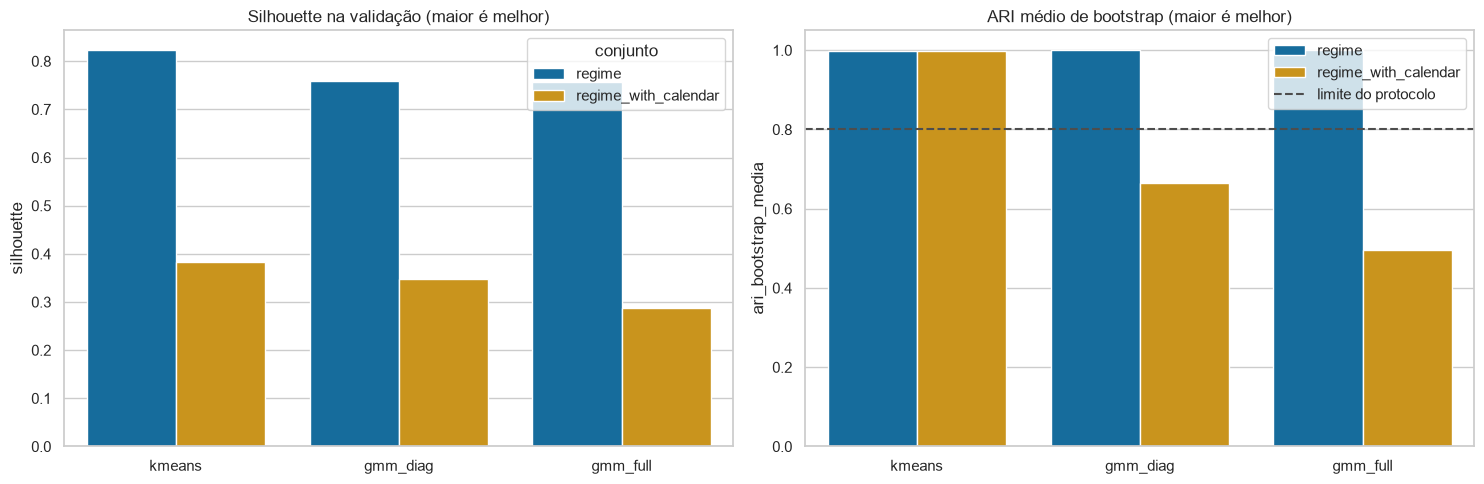

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_frame = comparison.reset_index()
plot_frame["rotulo"] = plot_frame["candidato"]
for ax, metric, title in [
    (axes[0], "silhouette", "Silhouette na validação (maior é melhor)"),
    (axes[1], "ari_bootstrap_media", "ARI médio de bootstrap (maior é melhor)"),
]:
    sns.barplot(data=plot_frame, x="rotulo", y=metric, hue="conjunto", ax=ax)
    ax.set(title=title, xlabel="", ylabel=metric)
axes[1].axhline(MIN_BOOTSTRAP_ARI, color="0.3", linestyle="--", label="limite do protocolo")
axes[1].legend()
fig.tight_layout()
save_figure(fig, "25_comparacao_candidatos.png")
plt.show()

## 5. Perfil dos regimes selecionados

Os grupos recebem nomes pela **assinatura elétrica** no treino (`order_by_profile`):
produção é o grupo de maior consumo mediano; entre os outros dois, o capacitivo é o de
maior energia reativa adiantada. Nomear pelo perfil, e não pela ordem de consumo, evita
que os dois regimes ociosos — com consumo quase igual — troquem de nome entre ajustes.
O calendário entra aqui apenas para **descrever** os regimes.

In [7]:
selected_model = reference_models[(SELECTED_SET, SELECTED)]
raw_train_labels = selected_model.predict(transformed[SELECTED_SET]["train"])
regime_order = md.order_by_profile(raw_train_labels, train)
REGIME_NAMES = md.REGIME_NAMES


def regimes_for(split_name: str) -> np.ndarray:
    raw_labels = selected_model.predict(transformed[SELECTED_SET][split_name])
    return np.vectorize(regime_order.__getitem__)(raw_labels)


labelled = {}
for name in ("train", "validation"):
    regimes = regimes_for(name)
    labelled[name] = splits[name].assign(
        regime=regimes, regime_name=[REGIME_NAMES[r] for r in regimes]
    )
profile_columns = [*pp.ENERGY_COLUMNS, *pp.POWER_FACTOR_COLUMNS]
regime_profile = labelled["train"].groupby("regime")[profile_columns].median()
regime_profile.insert(
    0, "proporcao", labelled["train"]["regime"].value_counts(normalize=True).sort_index()
)
regime_profile.index = [REGIME_NAMES[i] for i in regime_profile.index]
save_table(regime_profile, "modelagem_perfil_regimes.csv")
display(regime_profile.round(2))

,proporcao,usage_kwh,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,lagging_current_power_factor,leading_current_power_factor
ocioso indutivo,0.38,3.20,4.61,0.00,59.75,100.00
ocioso capacitivo,0.24,3.92,0.00,16.96,100.00,21.58
produção,0.38,60.66,28.69,0.00,91.84,100.00


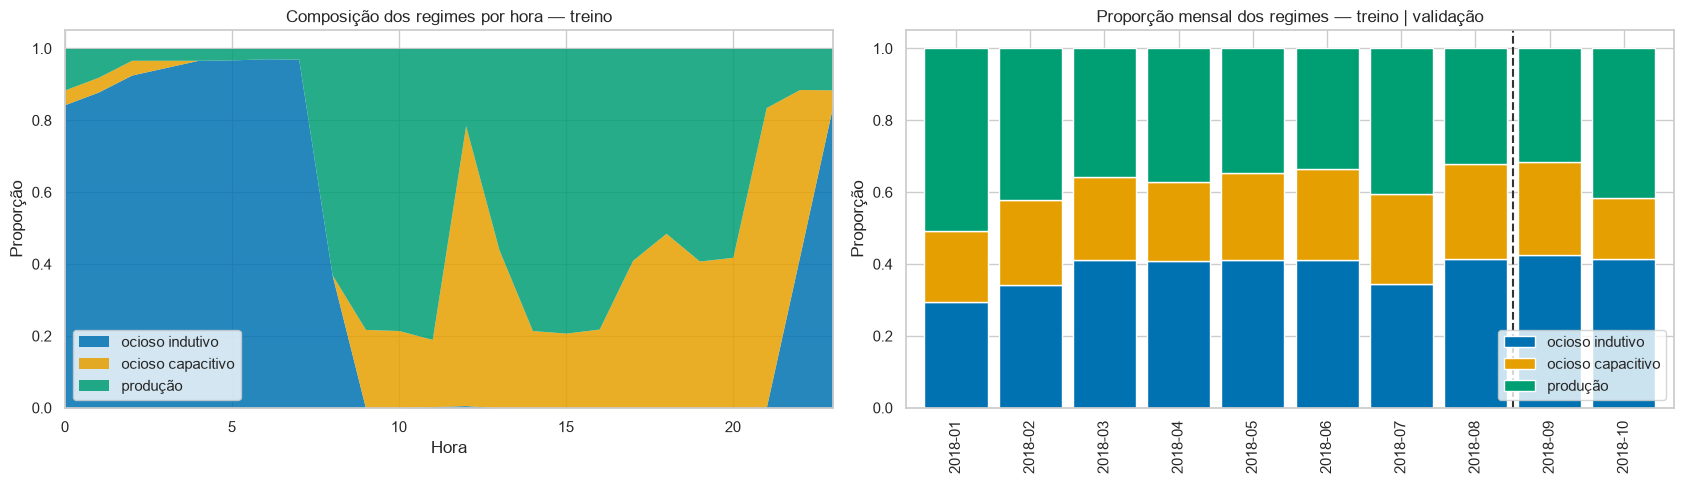

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
hourly = pd.crosstab(
    labelled["train"][pp.NSM] // 3_600, labelled["train"]["regime"], normalize="index"
)
hourly.columns = [REGIME_NAMES[i] for i in hourly.columns]
hourly.plot.area(ax=axes[0], color=REGIME_COLORS, alpha=0.85, linewidth=0)
axes[0].set(
    title="Composição dos regimes por hora — treino",
    xlabel="Hora",
    ylabel="Proporção",
    xlim=(0, 23),
)

monthly_frames = pd.concat(labelled.values())
# Timestamps marcam o fim do intervalo: agrupa pelo início para que 01/11 00:00 conte em outubro.
interval_start = monthly_frames[pp.TIMESTAMP_COLUMN] - pp.EXPECTED_FREQUENCY
monthly = pd.crosstab(interval_start.dt.to_period("M"), monthly_frames["regime"], normalize="index")
monthly.columns = [REGIME_NAMES[i] for i in monthly.columns]
monthly.index = monthly.index.astype(str)
monthly.plot.bar(stacked=True, ax=axes[1], color=REGIME_COLORS, width=0.85)
axes[1].axvline(7.5, color="0.2", linestyle="--")
axes[1].set(
    title="Proporção mensal dos regimes — treino | validação", xlabel="", ylabel="Proporção"
)
axes[1].legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "26_regimes_hora_mes.png")
plt.show()
save_table(monthly, "modelagem_regimes_por_mes.csv")

## 6. Anomalias

O Isolation Forest é ajustado no treino. O limiar vem da validação, de acordo com a
premissa de 1% de alertas.

In [9]:
X_anomaly = transformed["anomaly"]
anomaly_model = md.make_anomaly_model().fit(X_anomaly["train"])
validation_scores = -anomaly_model.score_samples(X_anomaly["validation"])
ANOMALY_THRESHOLD = float(np.quantile(validation_scores, 1 - ALERT_RATE))
print(f"Limiar (percentil {100 * (1 - ALERT_RATE):.0f} da validação): {ANOMALY_THRESHOLD:.4f}")

sensitivity = pd.DataFrame(
    [
        {
            "taxa_alerta": rate,
            "limiar": float(np.quantile(validation_scores, 1 - rate)),
            "alertas_validacao": round(rate * len(validation_scores)),
        }
        for rate in (0.005, 0.01, 0.02, 0.05)
    ]
)
save_table(sensitivity, "modelagem_sensibilidade_limiar.csv", index=False)
display(sensitivity.round(4))


def top_set(scores: np.ndarray) -> set[int]:
    return set(np.flatnonzero(scores >= np.quantile(scores, 1 - ALERT_RATE)))


reference_top = top_set(validation_scores)
jaccard = []
for seed in SEEDS[1:]:
    other = (
        -md.make_anomaly_model(seed).fit(X_anomaly["train"]).score_samples(X_anomaly["validation"])
    )
    other_top = top_set(other)
    jaccard.append(len(reference_top & other_top) / len(reference_top | other_top))
print(
    f"Jaccard do top 1% entre sementes: média {np.mean(jaccard):.3f}, mínimo {np.min(jaccard):.3f}"
)

Limiar (percentil 99 da validação): 0.6247


,taxa_alerta,limiar,alertas_validacao
0,0.005,0.6411,29
1,0.010,0.6247,59
2,0.020,0.6070,117
3,0.050,0.5728,293


Jaccard do top 1% entre sementes: média 0.874, mínimo 0.815


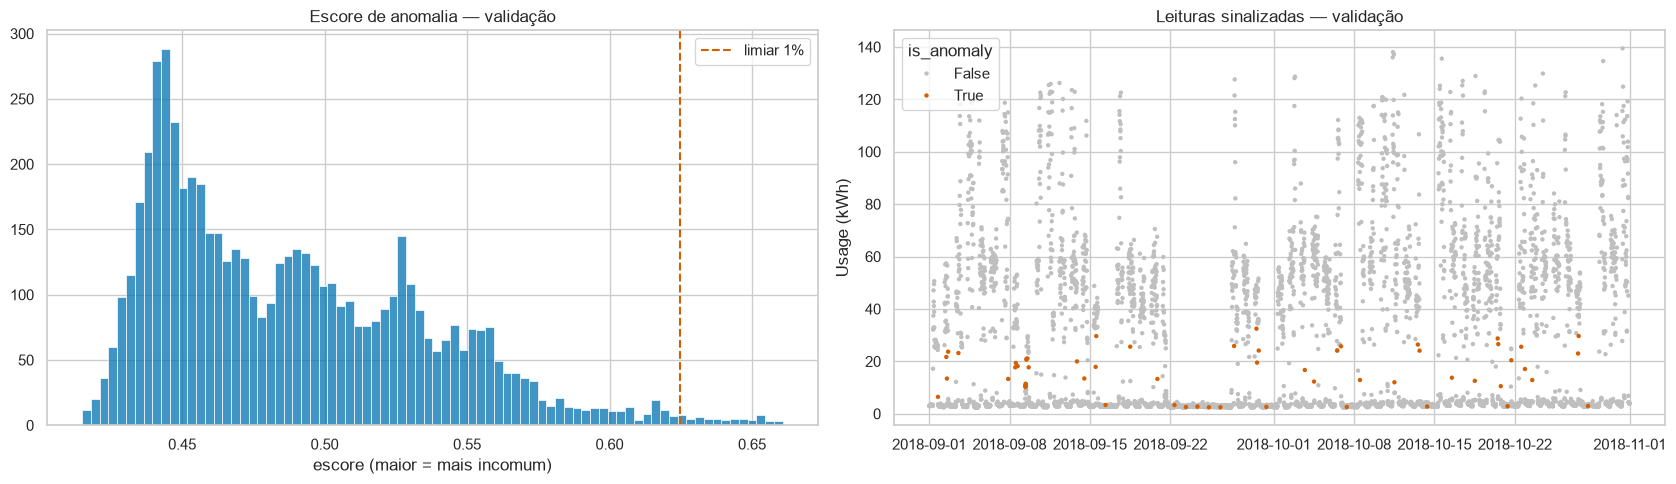

,alertas
regime,
ocioso indutivo,11
ocioso capacitivo,29
produção,19


,timestamp,day_of_week,usage_kwh,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,lagging_current_power_factor,leading_current_power_factor,regime_name,anomaly_score
1474,2018-09-16 08:45:00,Sunday,3.35,2.74,3.46,77.41,69.56,ocioso indutivo,0.660797
2818,2018-09-30 08:45:00,Sunday,2.63,2.02,2.34,79.31,74.71,ocioso indutivo,0.660314
3490,2018-10-07 08:45:00,Sunday,2.59,2.12,2.30,77.38,74.77,ocioso indutivo,0.659112
143,2018-09-02 12:00:00,Sunday,21.67,15.12,3.71,82.01,98.57,produção,0.657462
4162,2018-10-14 08:45:00,Sunday,2.77,2.12,2.30,79.41,76.94,ocioso indutivo,0.656622
4777,2018-10-20 18:30:00,Saturday,10.51,2.20,8.64,97.88,77.25,ocioso capacitivo,0.655622
2146,2018-09-23 08:45:00,Sunday,2.56,2.30,2.12,74.39,77.02,ocioso indutivo,0.654423
5428,2018-10-27 13:15:00,Saturday,29.66,12.17,7.67,92.51,96.82,produção,0.654369
148,2018-09-02 13:15:00,Sunday,13.43,2.92,9.86,97.72,80.61,ocioso capacitivo,0.654255
4751,2018-10-20 12:00:00,Saturday,28.73,17.35,4.90,85.60,98.58,produção,0.654104


In [10]:
val_anomalies = labelled["validation"].assign(
    anomaly_score=validation_scores, is_anomaly=validation_scores >= ANOMALY_THRESHOLD
)
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.histplot(validation_scores, bins=80, ax=axes[0], color=HIGH_CONTRAST_PALETTE[0])
axes[0].axvline(
    ANOMALY_THRESHOLD, color=HIGH_CONTRAST_PALETTE[3], linestyle="--", label="limiar 1%"
)
axes[0].set(
    title="Escore de anomalia — validação", xlabel="escore (maior = mais incomum)", ylabel=""
)
axes[0].legend()
sns.scatterplot(
    data=val_anomalies.sort_values("is_anomaly"),
    x=pp.TIMESTAMP_COLUMN,
    y=pp.USAGE,
    hue="is_anomaly",
    palette={False: "0.75", True: HIGH_CONTRAST_PALETTE[3]},
    s=10,
    linewidth=0,
    ax=axes[1],
)
axes[1].set(title="Leituras sinalizadas — validação", xlabel="", ylabel="Usage (kWh)")
fig.tight_layout()
save_figure(fig, "27_anomalias_validacao.png")
plt.show()

anomaly_context = val_anomalies[val_anomalies["is_anomaly"]].assign(
    hora=lambda f: f[pp.NSM] // 3_600
)
display(
    anomaly_context.groupby("regime")
    .size()
    .rename("alertas")
    .to_frame()
    .rename(index=dict(enumerate(REGIME_NAMES)))
)
display(
    anomaly_context.nlargest(10, "anomaly_score")[
        [pp.TIMESTAMP_COLUMN, pp.DAY_OF_WEEK, *profile_columns, "regime_name", "anomaly_score"]
    ]
)

### Recorrência dos alertas

Um alerta que se repete no mesmo dia da semana e horário, semana após semana, aponta
para um evento **programado** (rotina de manutenção, partida de equipamento), não para
uma falha isolada. A tabela agrupa os alertas da validação por dia da semana e horário
e conta em quantas semanas distintas cada combinação aparece.

In [11]:
weeks_in_validation = val_anomalies[pp.TIMESTAMP_COLUMN].dt.isocalendar().week.nunique()
recurrence = (
    anomaly_context.assign(
        horario=anomaly_context[pp.TIMESTAMP_COLUMN].dt.strftime("%H:%M"),
        semana=anomaly_context[pp.TIMESTAMP_COLUMN].dt.isocalendar().week,
    )
    .groupby([pp.DAY_OF_WEEK, "horario"])
    .agg(alertas=("semana", "size"), semanas_distintas=("semana", "nunique"))
    .sort_values("semanas_distintas", ascending=False)
)
recurring_mask = recurrence["semanas_distintas"] >= 3
recurring_share = recurrence.loc[recurring_mask, "alertas"].sum() / len(anomaly_context)
save_table(recurrence, "modelagem_recorrencia_alertas.csv")
display(recurrence.head(10))
print(f"Semanas na validação: {weeks_in_validation}")
print(f"Alertas em combinações dia×horário vistas em 3+ semanas: {recurring_share:.1%}")

alertas  semanas_distintas
day_of_week horario                            
Sunday      08:45          7                  7
Saturday    13:15          6                  6
            12:00          5                  5
Tuesday     12:15          3                  3
Thursday    12:15          3                  3
Monday      13:15          2                  2
Saturday    18:30          2                  2
            16:45          2                  2
Thursday    21:00          2                  2
Monday      08:45          1                  1

Semanas na validação: 10
Alertas em combinações dia×horário vistas em 3+ semanas: 40.7%


## 7. Congelamento da versão base

A partir deste ponto, os transformadores, o modelo de regimes e o limiar de anomalia não são reajustados. Esta versão base (v1.0) permite avaliar o período de teste e medir, de forma transparente, o efeito posterior do filtro de transições.

In [12]:
bundle = md.ModelBundle(
    regime_feature_set=SELECTED_SET,
    regime_preprocessor=fitted_preprocessors[SELECTED_SET],
    regime_model=selected_model,
    regime_order=regime_order,
    regime_names=REGIME_NAMES,
    anomaly_feature_set="anomaly",
    anomaly_preprocessor=fitted_preprocessors["anomaly"],
    anomaly_model=anomaly_model,
    anomaly_threshold=ANOMALY_THRESHOLD,
    metadata={
        "candidato": SELECTED,
        "motivo": selection_reason,
        "taxa_alerta": ALERT_RATE,
        "dados_sha256": raw_sha256,
        "treino_ate": pp.DEFAULT_SPLIT_BOUNDARIES[0].isoformat(),
        "versoes": {
            "python": platform.python_version(),
            "scikit-learn": sklearn.__version__,
            "pandas": pd.__version__,
            "numpy": np.__version__,
        },
    },
)
model_path = MODELS_DIR / "final_model.joblib"
joblib.dump(bundle, model_path)
reloaded = joblib.load(model_path)
check = reloaded.predict(validation.head(500))
assert (check["regime"].to_numpy() == labelled["validation"]["regime"].head(500).to_numpy()).all()
print(f"Salvo e verificado: {model_path.relative_to(ROOT)}")

Salvo e verificado: artifacts\models\final_model.joblib


## 8. Avaliação final no teste

Primeira e única leitura do período nov–dez.

In [13]:
test_result = reloaded.predict(test)
X_test = transformed[SELECTED_SET]["test"]
test_internal = internal_metrics(X_test, test_result["regime"].to_numpy())
test_alert_rate = float(test_result["is_anomaly"].mean())
shares = pd.DataFrame(
    {
        name: frame["regime"].value_counts(normalize=True).sort_index()
        for name, frame in {**labelled, "test": test_result}.items()
    }
).rename(index=dict(enumerate(REGIME_NAMES)))
display(
    pd.Series({**test_internal, "taxa_alerta_teste": test_alert_rate}, name="teste")
    .to_frame()
    .round(4)
)
display(shares.round(3))

,teste
silhouette,0.7677
davies_bouldin,0.3318
calinski_harabasz,33544.0817
menor_grupo,0.2433
taxa_alerta_teste,0.0084


,train,validation,test
regime,,,
ocioso indutivo,0.380,0.420,0.412
ocioso capacitivo,0.237,0.213,0.243
produção,0.383,0.366,0.344


### Concordância externa com `Load_Type`

`Load_Type` aparece pela primeira vez como referência. Para dar contexto aos números:

!!! note "Desvio do protocolo"
    O protocolo previa a regra de calendário com hora + status da semana + **mês**.
    Como novembro e dezembro não existem no treino, essa chave nunca casa no teste e a
    regra degenera em uma constante (ARI = 0). A referência usa hora + status da semana.
    O desvio afeta apenas a referência, não a seleção do modelo, que já estava congelada.

- **calendário (regra majoritária):** cada combinação hora × status da semana do treino
  recebe seu rótulo mais frequente, aplicado ao teste — quanto o calendário sozinho
  explica;
- **`regime_with_calendar`:** o candidato equivalente com calendário no input, que
  mostra o efeito de deixar o horário entrar na clusterização.

In [14]:
def calendar_keys(frame: pd.DataFrame) -> pd.Series:
    return (frame[pp.NSM] // 3_600).astype(str) + "|" + frame[pp.WEEK_STATUS]


calendar_rule = train.groupby(calendar_keys(train))[LABEL_COLUMN].agg(
    lambda s: s.value_counts().index[0]
)
calendar_test = calendar_keys(test).map(calendar_rule)
assert calendar_test.notna().all(), "Combinação de calendário ausente no treino."
assert calendar_test.nunique() > 1, "Regra de calendário degenerou em constante."

with_calendar_labels = reference_models[("regime_with_calendar", SELECTED)].predict(
    transformed["regime_with_calendar"]["test"]
)
truth = test[LABEL_COLUMN].to_numpy()
external = pd.DataFrame(
    [
        {
            "referencia": f"modelo selecionado ({SELECTED_SET}/{SELECTED})",
            "labels": test_result["regime"].to_numpy(),
        },
        {
            "referencia": f"sensibilidade (regime_with_calendar/{SELECTED})",
            "labels": with_calendar_labels,
        },
        {
            "referencia": "regra de calendário (usa rótulos do treino)",
            "labels": calendar_test.to_numpy(),
        },
    ]
)
external["ARI"] = [adjusted_rand_score(truth, labels) for labels in external["labels"]]
external["NMI"] = [normalized_mutual_info_score(truth, labels) for labels in external["labels"]]
external = external.drop(columns="labels").set_index("referencia")
save_table(external, "modelagem_concordancia_externa_teste.csv")
display(external.round(3))

,ARI,NMI
referencia,,
modelo selecionado (regime/kmeans),0.342,0.304
sensibilidade (regime_with_calendar/kmeans),0.355,0.315
regra de calendário (usa rótulos do treino),0.494,0.342


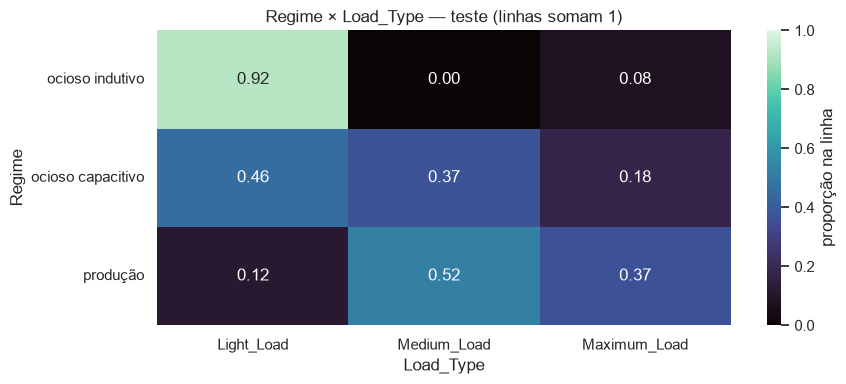

In [15]:
contingency = pd.crosstab(
    test_result["regime_name"], test_result[LABEL_COLUMN], normalize="index"
).reindex(index=REGIME_NAMES, columns=["Light_Load", "Medium_Load", "Maximum_Load"])
save_table(contingency, "modelagem_contingencia_teste.csv")

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(
    contingency,
    annot=True,
    fmt=".2f",
    cmap="mako",
    vmin=0,
    vmax=1,
    ax=ax,
    cbar_kws={"label": "proporção na linha"},
)
ax.set(title="Regime × Load_Type — teste (linhas somam 1)", xlabel="Load_Type", ylabel="Regime")
fig.tight_layout()
save_figure(fig, "28_contingencia_teste.png")
plt.show()

## 9. Avaliação e publicação da versão base

A primeira leitura do período de teste mede a generalização da versão congelada. Os artefatos v1.0 são publicados temporariamente para que a próxima seção possa aplicar e validar uma única alteração: remover alertas que coincidem com fronteiras de regime.

In [16]:
all_results = reloaded.predict(prepared)
results_columns = [
    pp.TIMESTAMP_COLUMN,
    pp.SPLIT_COLUMN,
    *pp.ELECTRICAL_COLUMNS,
    pp.NSM,
    pp.WEEK_STATUS,
    pp.DAY_OF_WEEK,
    LABEL_COLUMN,
    "regime",
    "regime_name",
    "regime_confidence",
    "anomaly_score",
    "is_anomaly_raw",
    "regime_boundary",
    "is_anomaly",
]
results_columns = [column for column in results_columns if column in all_results.columns]
all_results[results_columns].to_csv(
    PROCESSED_DIR / "analysis_results.csv", index=False, encoding="utf-8"
)
save_table(
    all_results[all_results["is_anomaly"]].sort_values("anomaly_score", ascending=False)[
        results_columns
    ],
    "modelagem_anomalias.csv",
    index=False,
)

final_metrics = {
    "modelo": {
        "conjunto": SELECTED_SET,
        "candidato": SELECTED,
        "motivo": selection_reason,
        "regimes": REGIME_NAMES,
    },
    "validacao": comparison.loc[(SELECTED_SET, SELECTED)].drop("elegivel").astype(float).to_dict(),
    "teste": {**{k: float(v) for k, v in test_internal.items()}, "taxa_alerta": test_alert_rate},
    "proporcao_regimes": {split: shares[split].round(4).to_dict() for split in shares},
    "anomalia": {
        "taxa_alerta_premissa": ALERT_RATE,
        "limiar": ANOMALY_THRESHOLD,
        "jaccard_sementes_media": float(np.mean(jaccard)),
    },
    "concordancia_externa_teste": external.round(4).to_dict(orient="index"),
    "dados_sha256": raw_sha256,
}
(METADATA_DIR / "final_metrics.json").write_text(
    json.dumps(final_metrics, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
)

manifest = write_manifest(DEFAULT_DATASET)
print(f"Manifesto: {len(manifest['artefatos'])} artefatos")
print(json.dumps(final_metrics, ensure_ascii=False, indent=2, default=str))

Manifesto: 75 artefatos
{
  "modelo": {
    "conjunto": "regime",
    "candidato": "kmeans",
    "motivo": "maior silhouette entre os elegíveis",
    "regimes": [
      "ocioso indutivo",
      "ocioso capacitivo",
      "produção"
    ]
  },
  "validacao": {
    "tempo_ajuste_s": 0.2348229999997784,
    "silhouette": 0.8226702885282484,
    "davies_bouldin": 0.2609881586087202,
    "calinski_harabasz": 44174.93198103584,
    "menor_grupo": 0.21311475409836064,
    "ari_sementes_media": 1.0,
    "ari_sementes_min": 1.0,
    "ari_bootstrap_media": 0.9991929762575994,
    "ari_bootstrap_min": 0.9978449691288427,
    "ari_temporal": 0.9989826366933094
  },
  "teste": {
    "silhouette": 0.7676972788234627,
    "davies_bouldin": 0.3318373573658568,
    "calinski_harabasz": 33544.08165710955,
    "menor_grupo": 0.24334016393442623,
    "taxa_alerta": 0.008367486338797815
  },
  "proporcao_regimes": {
    "train": {
      "ocioso indutivo": 0.3798,
      "ocioso capacitivo": 0.2371,
      "p

## 10. Filtro de alertas em transições de regime (v1.1)

**Por que testar este filtro?** Uma leitura de 15 minutos pode cobrir a troca entre dois estados operacionais. Ela fica naturalmente intermediária e pode parecer anômala, mesmo sem representar uma falha.

**Regra avaliada:** manter o alerta original apenas quando ele não coincidir com uma fronteira de regime. A regra só é ativada se os alertas em fronteira forem pelo menos três vezes mais frequentes do que seria esperado pela proporção dessas leituras na validação. O limiar de anomalia não é recalibrado.

In [17]:
MIN_LIFT = 3.0
PROFILE = [*pp.ENERGY_COLUMNS, *pp.POWER_FACTOR_COLUMNS]
predicted = reloaded.predict(prepared)
predicted["intervalo"] = ((predicted[pp.TIMESTAMP_COLUMN] - pp.EXPECTED_FREQUENCY).dt.strftime("%H:%M") + "–" + predicted[pp.TIMESTAMP_COLUMN].dt.strftime("%H:%M"))
print(f"Limiar v1.0: {bundle.anomaly_threshold:.4f}")

Limiar v1.0: 0.6247


In [18]:
def filter_summary(frame: pd.DataFrame) -> dict[str, float]:
    raw = frame["is_anomaly_raw"]
    boundary = frame["regime_boundary"]
    kept = raw & ~boundary
    return {
        "leituras": len(frame),
        "leituras_em_fronteira": boundary.mean(),
        "alertas_sem_filtro": int(raw.sum()),
        "alertas_em_fronteira": raw[boundary].sum() / max(raw.sum(), 1),
        "lift_fronteira": (raw[boundary].sum() / max(raw.sum(), 1)) / boundary.mean(),
        "alertas_com_filtro": int(kept.sum()),
        "taxa_sem_filtro": raw.mean(),
        "taxa_com_filtro": kept.mean(),
    }


by_split = pd.DataFrame(
    {name: filter_summary(predicted[predicted[pp.SPLIT_COLUMN] == name]) for name in pp.SPLIT_NAMES}
).T
save_table(by_split, "filtro_transicao_resumo.csv")
display(by_split)

validation_lift = by_split.loc["validation", "lift_fronteira"]
ENABLE_FILTER = bool(validation_lift >= MIN_LIFT)
print(
    f"Lift na validação: {validation_lift:.1f}× (mínimo {MIN_LIFT:.0f}×) -> filtro {'ATIVADO' if ENABLE_FILTER else 'NÃO ativado'}"
)

,leituras,leituras_em_fronteira,alertas_sem_filtro,alertas_em_fronteira,lift_fronteira,alertas_com_filtro,taxa_sem_filtro,taxa_com_filtro
train,23328.0,0.118570,471.0,0.796178,6.714840,96.0,0.020190,0.004115
validation,5856.0,0.092725,59.0,0.881356,9.505010,7.0,0.010075,0.001195
test,5856.0,0.098019,49.0,0.897959,9.161061,5.0,0.008367,0.000854


Lift na validação: 9.5× (mínimo 3×) -> filtro ATIVADO


In [19]:
validation = predicted[predicted[pp.SPLIT_COLUMN] == "validation"]
kept_validation = validation[validation["is_anomaly_raw"] & ~validation["regime_boundary"]]
print(f"Alertas mantidos na validação: {len(kept_validation)}")
display(
    kept_validation.sort_values("anomaly_score", ascending=False)[
        [pp.TIMESTAMP_COLUMN, pp.DAY_OF_WEEK, "intervalo", "regime_name", *PROFILE, "anomaly_score"]
    ]
)

Alertas mantidos na validação: 7


,timestamp,day_of_week,intervalo,regime_name,usage_kwh,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,lagging_current_power_factor,leading_current_power_factor,anomaly_score
24132,2018-09-09 09:15:00,Sunday,09:00–09:15,ocioso capacitivo,10.22,0.11,5.47,99.99,88.17,0.649145
24133,2018-09-09 09:30:00,Sunday,09:15–09:30,ocioso capacitivo,10.98,0.00,5.76,100.00,88.55,0.638523
24134,2018-09-09 09:45:00,Sunday,09:30–09:45,ocioso capacitivo,11.45,0.00,5.40,100.00,90.45,0.634699
24135,2018-09-09 10:00:00,Sunday,09:45–10:00,ocioso capacitivo,10.58,0.00,5.04,100.00,90.28,0.631821
24136,2018-09-09 10:15:00,Sunday,10:00–10:15,ocioso capacitivo,11.09,0.00,5.04,100.00,91.04,0.628310
28193,2018-10-21 16:30:00,Sunday,16:15–16:30,ocioso capacitivo,20.41,0.65,4.46,99.95,97.69,0.626261
26737,2018-10-06 12:30:00,Saturday,12:15–12:30,produção,24.12,0.79,1.94,99.95,99.68,0.624777


### Sensibilidade: recalibrar o limiar fora das fronteiras

Alternativa rejeitada pela regra: escolher um novo limiar para que 1% das leituras **fora
de fronteira** da validação vire alerta. A tabela mostra quantos alertas isso geraria e
quanto eles se repetem no mesmo dia da semana e intervalo (sinal de rotina, não de
evento).

In [20]:
non_boundary_val = validation[~validation["regime_boundary"]]
recalibrated_threshold = float(np.quantile(non_boundary_val["anomaly_score"], 0.99))
recalibrated = non_boundary_val[non_boundary_val["anomaly_score"] >= recalibrated_threshold]
weeks = recalibrated[pp.TIMESTAMP_COLUMN].dt.isocalendar().week
recurrence = (
    recalibrated.assign(semana=weeks)
    .groupby([pp.DAY_OF_WEEK, "intervalo"])["semana"]
    .transform("nunique")
)
sensitivity = pd.DataFrame(
    [
        {
            "opcao": "limiar v1.0 + filtro (escolhida)",
            "limiar": bundle.anomaly_threshold,
            "alertas_validacao": len(kept_validation),
            "recorrentes_3+_semanas": np.nan,
        },
        {
            "opcao": "limiar recalibrado fora de fronteira",
            "limiar": recalibrated_threshold,
            "alertas_validacao": len(recalibrated),
            "recorrentes_3+_semanas": float((recurrence >= 3).mean()),
        },
    ]
).set_index("opcao")
save_table(sensitivity, "filtro_transicao_sensibilidade.csv")
display(sensitivity)

,limiar,alertas_validacao,recorrentes_3+_semanas
opcao,,,
limiar v1.0 + filtro (escolhida),0.624720,7,NaN
limiar recalibrado fora de fronteira,0.595629,54,0.0


### 10.2 Os episódios suspeitos continuam sinalizados?

O notebook 04 apontou dois episódios no treino que merecem investigação (madrugadas de
15 a 23 de julho e manhã de 22 de maio). O filtro não pode apagá-los.

In [21]:
episodes = {
    "madrugadas 15–23/jul": (pd.Timestamp("2018-07-15"), pd.Timestamp("2018-07-24")),
    "manhã 22/mai": (pd.Timestamp("2018-05-22 08:00"), pd.Timestamp("2018-05-22 11:00")),
}
rows = []
for name, (start, end) in episodes.items():
    window = predicted[
        (predicted[pp.TIMESTAMP_COLUMN] > start) & (predicted[pp.TIMESTAMP_COLUMN] <= end)
    ]
    if name.startswith("madrugadas"):
        window = window[window[pp.TIMESTAMP_COLUMN].dt.hour < 6]
    rows.append(
        {
            "episodio": name,
            "alertas_sem_filtro": int(window["is_anomaly_raw"].sum()),
            "alertas_com_filtro": int(
                (window["is_anomaly_raw"] & ~window["regime_boundary"]).sum()
            ),
        }
    )
episode_check = pd.DataFrame(rows).set_index("episodio")
display(episode_check)

,alertas_sem_filtro,alertas_com_filtro
episodio,,
madrugadas 15–23/jul,29,22
manhã 22/mai,7,5


### 10.3 Teste (com ressalva de independência)

In [22]:
test = predicted[predicted[pp.SPLIT_COLUMN] == "test"]
kept_test = test[test["is_anomaly_raw"] & ~test["regime_boundary"]]
print(
    f"Teste: {int(test['is_anomaly_raw'].sum())} alertas sem filtro -> {len(kept_test)} com filtro"
)
display(
    kept_test.sort_values("anomaly_score", ascending=False)[
        [pp.TIMESTAMP_COLUMN, pp.DAY_OF_WEEK, "intervalo", "regime_name", *PROFILE, "anomaly_score"]
    ]
)

Teste: 49 alertas sem filtro -> 5 com filtro


,timestamp,day_of_week,intervalo,regime_name,usage_kwh,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,lagging_current_power_factor,leading_current_power_factor,anomaly_score
32775,2018-12-08 10:00:00,Saturday,09:45–10:00,ocioso capacitivo,31.43,0.18,4.43,100.0,99.02,0.629478
32103,2018-12-01 10:00:00,Saturday,09:45–10:00,ocioso capacitivo,28.58,0.04,5.83,100.0,97.98,0.628649
32776,2018-12-08 10:15:00,Saturday,10:00–10:15,ocioso capacitivo,31.57,0.22,4.18,100.0,99.13,0.627730
32104,2018-12-01 10:15:00,Saturday,10:00–10:15,ocioso capacitivo,28.73,0.00,5.94,100.0,97.93,0.625478
32105,2018-12-01 10:30:00,Saturday,10:15–10:30,ocioso capacitivo,29.56,0.00,5.11,100.0,98.54,0.625225


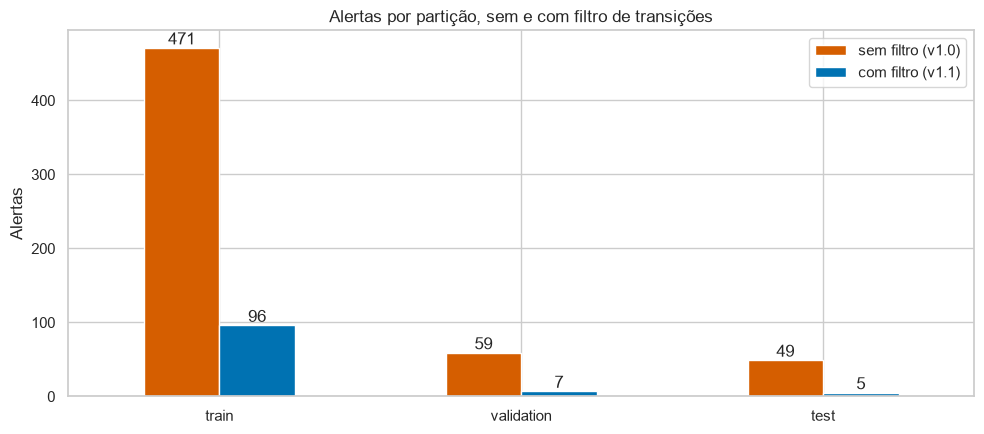

In [23]:
fig, ax = plt.subplots(figsize=(10, 4.5))
plot = by_split[["alertas_sem_filtro", "alertas_com_filtro"]].reindex(pp.SPLIT_NAMES)
plot.plot.bar(ax=ax, color=[HIGH_CONTRAST_PALETTE[3], HIGH_CONTRAST_PALETTE[0]], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
ax.set(title="Alertas por partição, sem e com filtro de transições", xlabel="", ylabel="Alertas")
ax.legend(["sem filtro (v1.0)", "com filtro (v1.1)"])
fig.tight_layout()
fig.savefig(IMAGES_DIR / "32_filtro_transicao.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.4 Publicação da v1.1

Se a regra ativou o filtro, o modelo é republicado com `transition_filter=True`.
`analysis_results.csv` passa a ter `is_anomaly` filtrado, mantendo `is_anomaly_raw` e
`regime_boundary`. `final_metrics.json` ganha o bloco `filtro_transicao`; as métricas do
protocolo original ficam inalteradas.

In [24]:
if ENABLE_FILTER:
    bundle.transition_filter = True
    bundle.metadata = {
        **bundle.metadata,
        "versao": "1.1",
        "mudancas": ["filtro de alertas em fronteira de regime (notebook 05)"],
    }
    joblib.dump(bundle, MODELS_DIR / "final_model.joblib")

    reloaded = joblib.load(MODELS_DIR / "final_model.joblib")
    results = reloaded.predict(prepared)
    assert reloaded.transition_filter
    assert not (results["is_anomaly"] & results["regime_boundary"]).any()

    columns = [
        pp.TIMESTAMP_COLUMN,
        pp.SPLIT_COLUMN,
        *pp.ELECTRICAL_COLUMNS,
        pp.NSM,
        pp.WEEK_STATUS,
        pp.DAY_OF_WEEK,
        LABEL_COLUMN,
        "regime",
        "regime_name",
        "regime_confidence",
        "anomaly_score",
        "is_anomaly_raw",
        "regime_boundary",
        "is_anomaly",
    ]
    columns = [column for column in columns if column in results.columns]
    results[columns].to_csv(PROCESSED_DIR / "analysis_results.csv", index=False, encoding="utf-8")

    metrics_path = METADATA_DIR / "final_metrics.json"
    final_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    final_metrics["filtro_transicao"] = {
        "versao_modelo": "1.1",
        "ativo": True,
        "regra": f"lift de alertas em fronteira >= {MIN_LIFT:.0f}x na validação",
        "lift_validacao": float(validation_lift),
        "limiar": bundle.anomaly_threshold,
        "por_particao": by_split[
            ["alertas_sem_filtro", "alertas_com_filtro", "taxa_sem_filtro", "taxa_com_filtro"]
        ].to_dict(orient="index"),
        "ressalva_teste": "recorrência analisada no ano todo; teste não totalmente independente",
    }
    metrics_path.write_text(
        json.dumps(final_metrics, ensure_ascii=False, indent=2, default=float), encoding="utf-8"
    )
    manifest = write_manifest(DEFAULT_DATASET)
    print(f"v1.1 publicada; manifesto com {len(manifest['artefatos'])} artefatos.")
else:
    print("Filtro não ativado; v1.0 permanece publicada.")

v1.1 publicada; manifesto com 75 artefatos.


### 10.5 Resultado do filtro

- **Filtro ativado pela regra:** na validação, 88% dos alertas caem em fronteira de
  regime, contra 9% das leituras (lift de 9,5×).
- **Volume:** 59 → 7 alertas na validação e 49 → 5 no teste (de ~1% para ~0,1% das
  leituras), sem mudar o limiar.
- **O que sobra quase sempre tem uma assinatura comum:** 10 dos 12 alertas são carga
  média (10–31 kWh) com corrente adiantada em manhãs de fim de semana (09/09, 01/12 e
  08/12) — o mesmo perfil do episódio de 22/05. Os outros dois também são fim de semana
  com carga média: sábado 06/10 às 12:30 e domingo 21/10 às 16:30. Compatível com operação parcial com a compensação de reativos
  ligada; é o tipo de evento que vale levar à operação.
- **Custo do filtro:** no episódio das madrugadas de julho, 7 de 29 alertas caem porque o
  próprio evento gera trocas de regime; 22 continuam sinalizados, então o episódio segue
  visível. Uma falha que coincida exatamente com uma transição não alarma — por isso
  `is_anomaly_raw` e `anomaly_score` continuam publicados.
- **Alternativa rejeitada:** recalibrar o limiar fora das fronteiras geraria 54 alertas na
  validação, nenhum recorrente, mas a maioria pouco incomum — volume alto sem ganho claro.

**Pendente com a operação:** confirmar, na triagem do notebook 04, que transições não são
de interesse. Se forem, basta republicar com `transition_filter=False`.

## 11. Conclusões e limitações

O modelo final v1.1 combina a segmentação não supervisionada, o limiar calibrado na validação e o filtro de alertas em fronteiras de regime. Os alertas mantidos são sinais para investigação operacional, não diagnósticos de falha. A revisão dos nomes dos regimes e dos alertas priorizados ocorre no notebook 04.